<a href="https://colab.research.google.com/github/DalpesCS50/trab_estagio4_health-insurance-claims-prediction/blob/main/notebooks/KNN_com_PCA_%E2%80%94_HEALTH_INSURANCE.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# KNN com PCA — HEALTH INSURANCE

Nesta etapa, será avaliado o K-Nearest Neighbors Regressor após a
redução de dimensionalidade por Análise de Componentes Principais (PCA),
para prever claim a partir das 12 preditoras originais.

Serão mantidos a preparação dos dados, a divisão por grupos e os folds
utilizados no KNN sem PCA. O objetivo é comparar o desempenho após
acrescentar a redução de dimensionalidade.

A imputação, o escalonamento, a codificação e o PCA serão ajustados
somente no treinamento e novamente em cada treinamento interno da
validação cruzada.

Será adotado o critério de retenção de pelo menos 95% da variância
das preditoras preparadas. A quantidade de componentes será determinada
em cada ajuste, podendo variar entre folds.

O número de vizinhos será escolhido pelo menor RMSE médio de validação,
utilizando os mesmos candidatos avaliados no KNN sem PCA. O teste
externo será reservado para a avaliação final.

## Resultados anteriores no teste externo

| Modelo | R² | RMSE | MAE |
|---|---:|---:|---:|
| Regressão linear | 0,754392 | 6.018,86 | 3.967,54 |
| KNN sem PCA — k = 5 | 0,941664 | 2.933,33 | 1.041,57 |

A variância retida pelo PCA não representa a proporção de claim
explicada nem garante melhoria preditiva. Seu efeito será avaliado
pelas métricas de erro e pelo R².

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import (
    GroupShuffleSplit,
    GroupKFold,
    GridSearchCV,
    cross_validate
)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, MinMaxScaler
from sklearn.impute import SimpleImputer
from sklearn.decomposition import PCA
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error


def rmse_score(real, previsto):
    return float(np.sqrt(mean_squared_error(real, previsto)))

In [2]:
def carrega_dados():
    url = (
        'https://raw.githubusercontent.com/DalpesCS50/'
        'trab_estagio4_health-insurance-claims-prediction/'
        'refs/heads/main/data/healthinsurance.csv'
    )
    df_raw = pd.read_csv(url)

    esperado = [
        'age', 'sex', 'weight', 'bmi', 'hereditary_diseases',
        'no_of_dependents', 'smoker', 'city', 'bloodpressure',
        'diabetes', 'regular_ex', 'job_title', 'claim'
    ]

    assert set(df_raw.columns) == set(esperado), 'Conferir as colunas da base.'
    df_raw = df_raw[esperado].copy()

    assert df_raw['claim'].notna().all(), 'A resposta contém ausências.'
    assert df_raw.index.is_unique

    # Identificar cópias exatas antes de qualquer tratamento.
    chaves = pd.MultiIndex.from_frame(df_raw)
    grupos = pd.Series(
        pd.factorize(chaves, sort=False)[0],
        index=df_raw.index,
        name='grupo'
    )

    X = df_raw.drop(columns='claim').copy()

    # Manter o tratamento adotado nos modelos anteriores.
    X['bloodpressure'] = X['bloodpressure'].mask(
        X['bloodpressure'].eq(0)
    )

    y = df_raw['claim'].copy()

    return df_raw, X, y, grupos


df_raw, X, y, grupos = carrega_dados()

display(X.head())
display(y.head().to_frame())

print('Dimensão de X:', X.shape, '| dimensão de y:', y.shape)
print('Linhas repetidas além da primeira:', df_raw.duplicated().sum())
print('Grupos de linhas distintas:', grupos.nunique())
print('Zeros originais em bloodpressure:', df_raw['bloodpressure'].eq(0).sum())

display(X.isna().sum())

,age,sex,weight,bmi,hereditary_diseases,no_of_dependents,smoker,city,bloodpressure,diabetes,regular_ex,job_title
0,60.0,male,64,24.3,NoDisease,1,0,NewYork,72.0,0,0,Actor
1,49.0,female,75,22.6,NoDisease,1,0,Boston,78.0,1,1,Engineer
2,32.0,female,64,17.8,Epilepsy,2,1,Phildelphia,88.0,1,1,Academician
3,61.0,female,53,36.4,NoDisease,1,1,Pittsburg,72.0,1,0,Chef
4,19.0,female,50,20.6,NoDisease,0,0,Buffalo,82.0,1,0,HomeMakers


,claim
0,13112.6
1,9567.0
2,32734.2
3,48517.6
4,1731.7


Dimensão de X: (15000, 12) | dimensão de y: (15000,)
Linhas repetidas além da primeira: 1096
Grupos de linhas distintas: 13904
Zeros originais em bloodpressure: 756


,0
age,396
sex,0
weight,0
bmi,956
hereditary_diseases,0
no_of_dependents,0
smoker,0
city,0
bloodpressure,756
diabetes,0


In [3]:
separacao = GroupShuffleSplit(
    n_splits=1,
    train_size=0.7,
    random_state=1
)

idx_train, idx_test = next(
    separacao.split(X, y, groups=grupos)
)

X_train = X.iloc[idx_train].copy()
X_test = X.iloc[idx_test].copy()
y_train = y.iloc[idx_train].copy()
y_test = y.iloc[idx_test].copy()

grupos_train = grupos.iloc[idx_train].copy()
grupos_test = grupos.iloc[idx_test].copy()

# Conferir alinhamento e separação dos grupos.
assert X_train.index.equals(y_train.index)
assert X_test.index.equals(y_test.index)
assert set(grupos_train).isdisjoint(set(grupos_test))
assert len(X_train) + len(X_test) == len(X)

# Conferir os tamanhos dos modelos anteriores.
assert X_train.shape == (10527, 12), 'Divisão diferente da anterior.'
assert X_test.shape == (4473, 12), 'Divisão diferente da anterior.'

# Definir os mesmos folds por grupos para a validação.
cv = GroupKFold(n_splits=10)
assert grupos_train.nunique() >= cv.n_splits

print(
    'Treinamento:', X_train.shape,
    f'({len(X_train) / len(X):.2%} das linhas)'
)
print(
    'Teste:', X_test.shape,
    f'({len(X_test) / len(X):.2%} das linhas)'
)
print('Grupos separados e índices de X e y alinhados.')
print('Validação definida com dez folds por grupos.')

display(X_test.head())

Treinamento: (10527, 12) (70.18% das linhas)
Teste: (4473, 12) (29.82% das linhas)
Grupos separados e índices de X e y alinhados.
Validação definida com dez folds por grupos.


,age,sex,weight,bmi,hereditary_diseases,no_of_dependents,smoker,city,bloodpressure,diabetes,regular_ex,job_title
4,19.0,female,50,20.6,NoDisease,0,0,Buffalo,82.0,1,0,HomeMakers
5,42.0,female,89,37.9,NoDisease,0,0,AtlanticCity,78.0,0,0,Dancer
6,18.0,male,59,23.8,NoDisease,0,0,Portland,64.0,0,0,Singer
7,21.0,male,52,26.8,NoDisease,0,0,Cambridge,74.0,1,0,Actor
12,19.0,male,45,24.6,NoDisease,1,0,York,NaN,0,1,Student


In [4]:
def cria_modelo_knn_pca(n_neighbors=5):
    idade_bmi = Pipeline([
        ('imputacao', SimpleImputer(strategy='median')),
        ('escala', MinMaxScaler())
    ])

    peso_pressao = Pipeline([
        ('imputacao', SimpleImputer(strategy='median')),
        ('escala', StandardScaler())
    ])

    categoricas = Pipeline([
        ('imputacao', SimpleImputer(strategy='most_frequent')),
        ('codificacao', OneHotEncoder(
            drop='first',
            handle_unknown='ignore',
            sparse_output=False
        ))
    ])

    preparacao = ColumnTransformer([
        ('idade_bmi', idade_bmi, ['age', 'bmi']),
        ('peso_pressao', peso_pressao, ['weight', 'bloodpressure']),
        ('numericas', 'passthrough', [
            'no_of_dependents', 'smoker', 'diabetes', 'regular_ex'
        ]),
        ('categoricas', categoricas, [
            'sex', 'hereditary_diseases', 'city', 'job_title'
        ])
    ], remainder='drop', verbose_feature_names_out=False)

    return Pipeline([
        ('preprocessamento', preparacao),
        ('pca', PCA(
            n_components=0.95,
            svd_solver='full',
            whiten=False
        )),
        ('knn', KNeighborsRegressor(n_neighbors=n_neighbors))
    ])

In [5]:
knn_pca_5 = cria_modelo_knn_pca(n_neighbors=5)

cv_knn_pca_5 = cross_validate(
    estimator=knn_pca_5,
    X=X_train,
    y=y_train,
    groups=grupos_train,
    cv=cv,
    scoring=(
        'r2',
        'neg_root_mean_squared_error',
        'neg_mean_absolute_error'
    ),
    return_estimator=True,
    n_jobs=-1,
    error_score='raise'
)

modelos_folds = cv_knn_pca_5['estimator']

resultados_knn_pca_5 = pd.DataFrame({
    'fold': np.arange(1, cv.n_splits + 1),
    'R2': cv_knn_pca_5['test_r2'],
    'RMSE': -cv_knn_pca_5['test_neg_root_mean_squared_error'],
    'MAE': -cv_knn_pca_5['test_neg_mean_absolute_error'],
    'colunas_antes_PCA': [
        modelo.named_steps['pca'].n_features_in_
        for modelo in modelos_folds
    ],
    'componentes_retidos': [
        modelo.named_steps['pca'].n_components_
        for modelo in modelos_folds
    ],
    'variancia_retida': [
        modelo.named_steps['pca'].explained_variance_ratio_.sum()
        for modelo in modelos_folds
    ]
})

print('KNN com PCA e k = 5 — validação cruzada por grupos')
display(resultados_knn_pca_5)

print('Resumo das métricas nos dez folds:')
display(
    resultados_knn_pca_5[['R2', 'RMSE', 'MAE']].agg(['mean', 'std'])
)

assert (resultados_knn_pca_5['variancia_retida'] >= 0.95).all()
print('Retenção de pelo menos 95% da variância conferida em cada fold.')

KNN com PCA e k = 5 — validação cruzada por grupos


,fold,R2,RMSE,MAE,colunas_antes_PCA,componentes_retidos,variancia_retida
0,1,0.919946,3406.222607,1353.561975,142,94,0.951156
1,2,0.914233,3509.522055,1361.851757,142,94,0.950953
2,3,0.915351,3492.950702,1340.410047,142,94,0.950888
3,4,0.910538,3488.567269,1339.805242,142,94,0.951019
4,5,0.928842,3354.206868,1249.008528,142,94,0.950866
5,6,0.916822,3418.662935,1442.053789,142,94,0.951024
6,7,0.927032,3325.585245,1279.337037,142,94,0.950931
7,8,0.923429,3419.836674,1385.190494,142,94,0.950682
8,9,0.937361,3134.729011,1254.766331,142,94,0.950409
9,10,0.933122,3131.524890,1301.355913,142,94,0.950873


Resumo das métricas nos dez folds:


,R2,RMSE,MAE
mean,0.922668,3368.180825,1330.734111
std,0.008796,137.120039,60.532644


Retenção de pelo menos 95% da variância conferida em cada fold.


In [6]:
knn_pca_10 = cria_modelo_knn_pca(n_neighbors=10)

cv_knn_pca_10 = cross_validate(
    estimator=knn_pca_10,
    X=X_train,
    y=y_train,
    groups=grupos_train,
    cv=cv,
    scoring=(
        'r2',
        'neg_root_mean_squared_error',
        'neg_mean_absolute_error'
    ),
    return_estimator=True,
    n_jobs=-1,
    error_score='raise'
)

modelos_folds_10 = cv_knn_pca_10['estimator']

resultados_knn_pca_10 = pd.DataFrame({
    'fold': np.arange(1, cv.n_splits + 1),
    'R2': cv_knn_pca_10['test_r2'],
    'RMSE': -cv_knn_pca_10['test_neg_root_mean_squared_error'],
    'MAE': -cv_knn_pca_10['test_neg_mean_absolute_error'],
    'colunas_antes_PCA': [
        modelo.named_steps['pca'].n_features_in_
        for modelo in modelos_folds_10
    ],
    'componentes_retidos': [
        modelo.named_steps['pca'].n_components_
        for modelo in modelos_folds_10
    ],
    'variancia_retida': [
        modelo.named_steps['pca'].explained_variance_ratio_.sum()
        for modelo in modelos_folds_10
    ]
})

print('KNN com PCA e k = 10 — validação cruzada por grupos')
display(resultados_knn_pca_10)

print('Resumo das métricas nos dez folds:')
display(
    resultados_knn_pca_10[['R2', 'RMSE', 'MAE']].agg(['mean', 'std'])
)

assert (resultados_knn_pca_10['variancia_retida'] >= 0.95).all()
print('Retenção de pelo menos 95% da variância conferida em cada fold.')

KNN com PCA e k = 10 — validação cruzada por grupos


,fold,R2,RMSE,MAE,colunas_antes_PCA,componentes_retidos,variancia_retida
0,1,0.872749,4294.496707,2289.960095,142,94,0.951156
1,2,0.881548,4124.382139,2212.024720,142,94,0.950953
2,3,0.877919,4194.738089,2255.363162,142,94,0.950888
3,4,0.874350,4134.378878,2199.524815,142,94,0.951019
4,5,0.888898,4191.207867,2270.190902,142,94,0.950866
5,6,0.853984,4529.512327,2489.757236,142,94,0.951024
6,7,0.877062,4316.643726,2244.969050,142,94,0.950931
7,8,0.883218,4223.381002,2247.181702,142,94,0.950682
8,9,0.890374,4147.005872,2208.095789,142,94,0.950409
9,10,0.884358,4117.863812,2267.263413,142,94,0.950873


Resumo das métricas nos dez folds:


,R2,RMSE,MAE
mean,0.878446,4227.361042,2268.433088
std,0.010375,126.428758,83.130485


Retenção de pelo menos 95% da variância conferida em cada fold.


In [7]:
parametros_pca = {
    'knn__n_neighbors': [
        3, 5, 7, 9, 10, 15, 25, 50, 75, 100, 200, 300
    ]
}

# Conferir separação dos grupos e tamanho dos treinos internos.
for idx_treino, idx_val in cv.split(
    X_train, y_train, groups=grupos_train
):
    assert set(grupos_train.iloc[idx_treino]).isdisjoint(
        set(grupos_train.iloc[idx_val])
    )
    assert len(idx_treino) >= max(
        parametros_pca['knn__n_neighbors']
    )

grid_cv_pca = GridSearchCV(
    estimator=cria_modelo_knn_pca(),
    param_grid=parametros_pca,
    cv=cv,
    scoring={
        'RMSE': 'neg_root_mean_squared_error',
        'MAE': 'neg_mean_absolute_error',
        'R2': 'r2'
    },
    refit='RMSE',
    n_jobs=-1,
    return_train_score=True,
    error_score='raise'
)

# Somente o treinamento participa da busca.
grid_cv_pca.fit(
    X_train,
    y_train,
    groups=grupos_train
)

resultados_busca_pca = pd.DataFrame({
    'k': [
        p['knn__n_neighbors']
        for p in grid_cv_pca.cv_results_['params']
    ],
    'RMSE_treino': -grid_cv_pca.cv_results_['mean_train_RMSE'],
    'RMSE_validacao': -grid_cv_pca.cv_results_['mean_test_RMSE'],
    'desvio_RMSE_validacao': (
        grid_cv_pca.cv_results_['std_test_RMSE']
    ),
    'MAE_validacao': -grid_cv_pca.cv_results_['mean_test_MAE'],
    'R2_validacao': grid_cv_pca.cv_results_['mean_test_R2'],
    'posicao_RMSE': grid_cv_pca.cv_results_['rank_test_RMSE']
}).sort_values('k').reset_index(drop=True)

print('KNN com PCA — resultados da busca:')
display(resultados_busca_pca)

print(
    'Melhor k:',
    grid_cv_pca.best_params_['knn__n_neighbors']
)
print(
    'Menor RMSE médio de validação:',
    -grid_cv_pca.best_score_
)

# PCA do modelo escolhido, reajustado em todo o treinamento.
pca_final = grid_cv_pca.best_estimator_.named_steps['pca']

print('Colunas antes do PCA:', pca_final.n_features_in_)
print('Componentes retidos:', pca_final.n_components_)
print(
    'Variância retida:',
    f'{pca_final.explained_variance_ratio_.sum():.4%}'
)

print('Modelo escolhido reajustado em todo o treinamento.')
print('O conjunto de teste permanece reservado.')

KNN com PCA — resultados da busca:


,k,RMSE_treino,RMSE_validacao,desvio_RMSE_validacao,MAE_validacao,R2_validacao,posicao_RMSE
0,3,2023.164089,3068.819446,142.139477,958.394122,0.935739,1
1,5,2553.148810,3368.180825,130.083490,1330.734111,0.922668,2
2,7,2968.684865,3668.538562,129.066547,1671.203870,0.908328,3
3,9,3350.131756,4022.247788,122.141944,2058.319288,0.889903,4
4,10,3559.913002,4227.361042,119.940851,2268.433088,0.878446,5
5,15,4554.369989,5121.244177,153.819053,3167.212887,0.821851,6
6,25,5918.821736,6276.810382,141.639339,4135.861102,0.732438,7
7,50,7019.578576,7195.936107,139.044356,4803.292743,0.648510,8
8,75,7479.116724,7600.612439,136.821968,5110.870881,0.607860,9
9,100,7750.987558,7842.850597,154.332746,5298.083733,0.582564,10


Melhor k: 3
Menor RMSE médio de validação: 3068.8194458756093
Colunas antes do PCA: 142
Componentes retidos: 94
Variância retida: 95.0754%
Modelo escolhido reajustado em todo o treinamento.
O conjunto de teste permanece reservado.


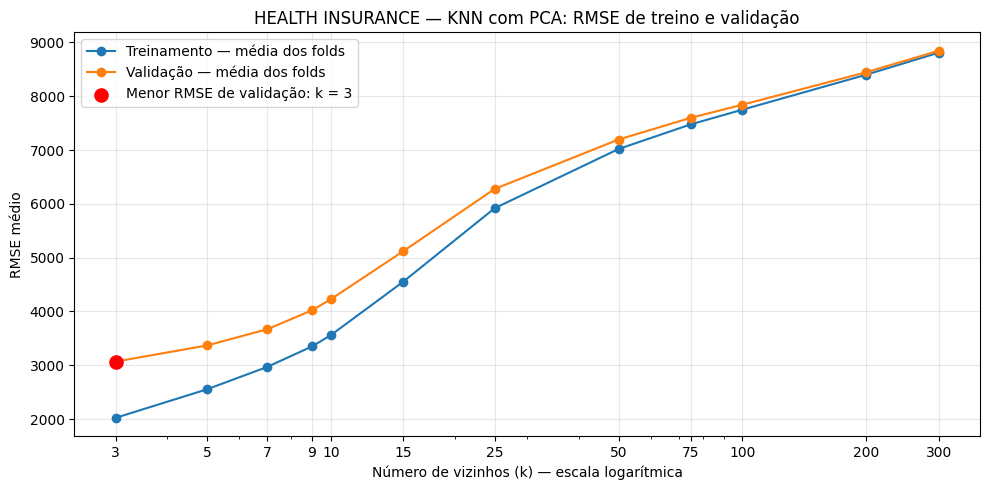

In [8]:
fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(
    resultados_busca_pca['k'],
    resultados_busca_pca['RMSE_treino'],
    marker='o',
    label='Treinamento — média dos folds'
)

ax.plot(
    resultados_busca_pca['k'],
    resultados_busca_pca['RMSE_validacao'],
    marker='o',
    label='Validação — média dos folds'
)

melhor_k_pca = grid_cv_pca.best_params_['knn__n_neighbors']
melhor_rmse_pca = -grid_cv_pca.best_score_

ax.scatter(
    melhor_k_pca,
    melhor_rmse_pca,
    color='red',
    s=90,
    zorder=5,
    label=f'Menor RMSE de validação: k = {melhor_k_pca}'
)

ax.set_xscale('log')
ax.set_xticks(resultados_busca_pca['k'])
ax.set_xticklabels(resultados_busca_pca['k'].astype(str))

ax.set_xlabel('Número de vizinhos (k) — escala logarítmica')
ax.set_ylabel('RMSE médio')
ax.set_title(
    'HEALTH INSURANCE — KNN com PCA: RMSE de treino e validação'
)
ax.grid(True, alpha=0.3)
ax.legend()

fig.tight_layout()
plt.show()

In [9]:
valores_k_pca = [
    p['knn__n_neighbors']
    for p in grid_cv_pca.cv_results_['params']
]

grid_knn_pca_df = pd.DataFrame(
    [
        -grid_cv_pca.cv_results_[f'split{i}_test_RMSE']
        for i in range(grid_cv_pca.n_splits_)
    ],
    columns=valores_k_pca,
    index=pd.Index(
        range(1, grid_cv_pca.n_splits_ + 1),
        name='fold'
    )
)

grid_knn_pca_df.columns.name = 'k'

print('KNN com PCA — RMSE de validação por fold e número de vizinhos:')
display(grid_knn_pca_df)

# Conferir as médias com os resultados da busca.
assert np.allclose(
    grid_knn_pca_df.mean().to_numpy(),
    -grid_cv_pca.cv_results_['mean_test_RMSE']
)

print('Médias conferidas com os resultados do GridSearchCV.')

KNN com PCA — RMSE de validação por fold e número de vizinhos:


k,3,5,7,9,10,15,25,50,75,100,200,300
fold,,,,,,,,,,,,
1,3068.302155,3406.222607,3732.197049,4097.979788,4294.496707,5260.911433,6228.297848,7227.500884,7615.197552,7825.481074,8452.751402,8825.913865
2,3280.906621,3509.522055,3641.775860,3950.922931,4124.382139,4990.285714,6166.950888,7078.992233,7408.519562,7663.344336,8271.662841,8685.671004
3,2992.990017,3492.950702,3790.695736,4036.909904,4194.738089,5056.047715,6357.308612,7284.488981,7698.573025,7923.042892,8532.014232,8936.059784
4,3307.049916,3488.567269,3656.145869,3948.818524,4134.378878,4824.384185,5971.554903,6863.146322,7315.081789,7541.916466,8063.338376,8446.922218
5,3065.701983,3354.206868,3645.062275,3978.831604,4191.207867,5258.845163,6322.029765,7270.347834,7753.494085,8026.322133,8780.692201,9164.063945
6,3086.610325,3418.662935,3924.461768,4303.854334,4529.512327,5382.414324,6474.259933,7203.247780,7625.821252,7833.965519,8409.185926,8765.070546
7,3108.614528,3325.585245,3674.648147,4113.560484,4316.643726,5194.997219,6423.350599,7379.457400,7736.757180,7997.253392,8551.209586,8987.387600
8,3069.896630,3419.836674,3684.326902,4038.873957,4223.381002,5080.342812,6157.595898,7118.416011,7523.095119,7757.805921,8392.413418,8810.832833
9,2868.166309,3134.729011,3467.747458,3862.383730,4147.005872,5153.694683,6374.709343,7315.481663,7697.772217,8049.634771,8634.338919,9058.437619


Médias conferidas com os resultados do GridSearchCV.


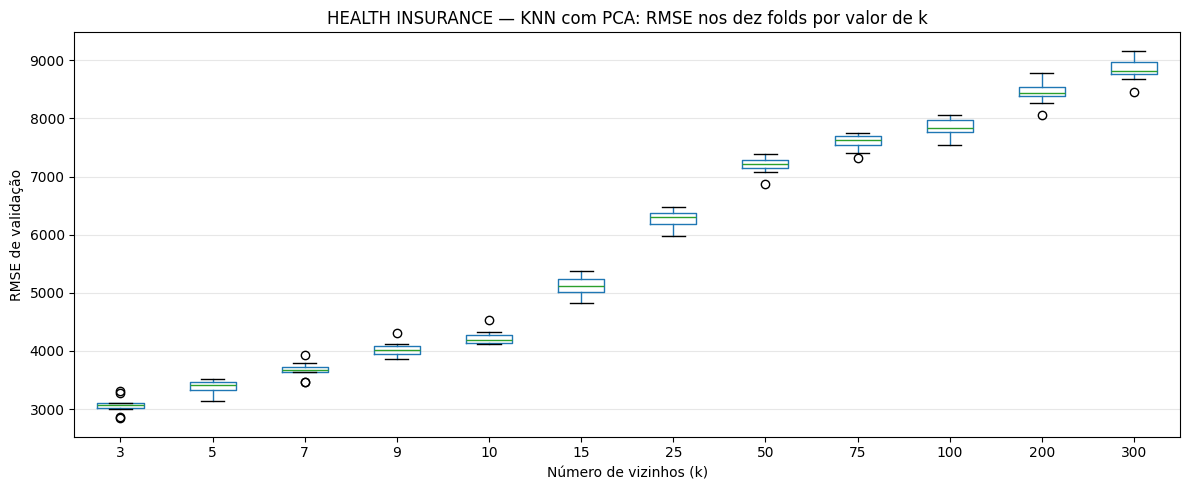

In [10]:
fig, ax = plt.subplots(figsize=(12, 5))

grid_knn_pca_df.boxplot(ax=ax, grid=False)

ax.set_xlabel('Número de vizinhos (k)')
ax.set_ylabel('RMSE de validação')
ax.set_title(
    'HEALTH INSURANCE — KNN com PCA: RMSE nos dez folds por valor de k'
)
ax.grid(axis='y', alpha=0.3)

fig.tight_layout()
plt.show()

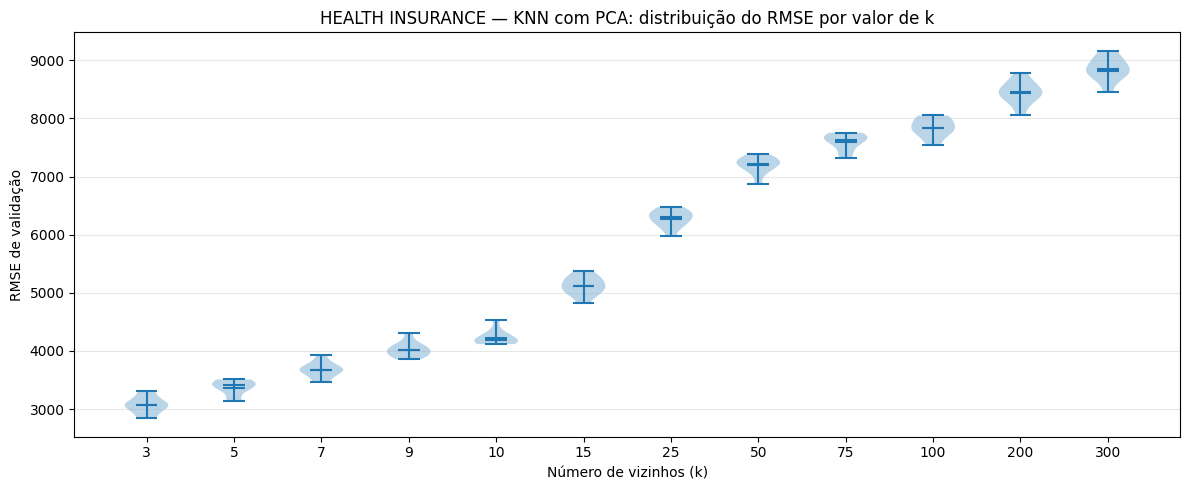

In [11]:
fig, ax = plt.subplots(figsize=(12, 5))

ax.violinplot(
    grid_knn_pca_df.to_numpy(),
    positions=np.arange(1, len(grid_knn_pca_df.columns) + 1),
    showmeans=True,
    showmedians=True
)

ax.set_xticks(
    np.arange(1, len(grid_knn_pca_df.columns) + 1)
)
ax.set_xticklabels(
    grid_knn_pca_df.columns.astype(str)
)

ax.set_xlabel('Número de vizinhos (k)')
ax.set_ylabel('RMSE de validação')
ax.set_title(
    'HEALTH INSURANCE — KNN com PCA: distribuição do RMSE por valor de k'
)
ax.grid(axis='y', alpha=0.3)

fig.tight_layout()
plt.show()

In [12]:
# Confirmar o parâmetro escolhido pela validação.
melhor_k_pca = grid_cv_pca.best_params_['knn__n_neighbors']
assert melhor_k_pca == 3, 'O melhor k difere do resultado conferido.'

# Avaliação final no teste reservado.
knn_pca_pred = grid_cv_pca.predict(X_test)

metricas_knn_pca_teste = {
    'RMSE': rmse_score(y_test, knn_pca_pred),
    'MAE': mean_absolute_error(y_test, knn_pca_pred),
    'R2': r2_score(y_test, knn_pca_pred)
}

print(f'KNN com PCA e k = {melhor_k_pca} — teste externo')
print(f"RMSE: {metricas_knn_pca_teste['RMSE']:.6f}")
print(f"MAE:  {metricas_knn_pca_teste['MAE']:.6f}")
print(f"R²:   {metricas_knn_pca_teste['R2']:.6f}")

# Resultados anteriores, registrados no mesmo conjunto de teste.
comparacao_tres_modelos = pd.DataFrame([
    {
        'Modelo': 'Regressão linear',
        'RMSE': 6018.863496,
        'MAE': 3967.544566,
        'R2': 0.754392
    },
    {
        'Modelo': 'KNN sem PCA — k = 5',
        'RMSE': 2933.325932,
        'MAE': 1041.565844,
        'R2': 0.941664
    },
    {
        'Modelo': f'KNN com PCA — k = {melhor_k_pca}',
        **metricas_knn_pca_teste
    }
]).set_index('Modelo')

print('\nComparação dos três modelos no teste:')
display(comparacao_tres_modelos)

# Comparar validação e teste do KNN com PCA selecionado.
i_melhor_pca = grid_cv_pca.best_index_

validacao_teste_knn_pca = pd.DataFrame([
    {
        'Avaliação': 'Média da validação cruzada',
        'RMSE': -grid_cv_pca.cv_results_[
            'mean_test_RMSE'
        ][i_melhor_pca],
        'MAE': -grid_cv_pca.cv_results_[
            'mean_test_MAE'
        ][i_melhor_pca],
        'R2': grid_cv_pca.cv_results_[
            'mean_test_R2'
        ][i_melhor_pca]
    },
    {
        'Avaliação': 'Teste externo',
        **metricas_knn_pca_teste
    }
]).set_index('Avaliação')

print('\nKNN com PCA — validação e teste:')
display(validacao_teste_knn_pca)

pca_final = grid_cv_pca.best_estimator_.named_steps['pca']

print('\nComponentes retidos:', pca_final.n_components_)
print(
    'Variância retida:',
    f'{pca_final.explained_variance_ratio_.sum():.4%}'
)

KNN com PCA e k = 3 — teste externo
RMSE: 3033.073764
MAE:  898.495983
R²:   0.937629

Comparação dos três modelos no teste:


,RMSE,MAE,R2
Modelo,,,
Regressão linear,6018.863496,3967.544566,0.754392
KNN sem PCA — k = 5,2933.325932,1041.565844,0.941664
KNN com PCA — k = 3,3033.073764,898.495983,0.937629



KNN com PCA — validação e teste:


,RMSE,MAE,R2
Avaliação,,,
Média da validação cruzada,3068.819446,958.394122,0.935739
Teste externo,3033.073764,898.495983,0.937629



Componentes retidos: 94
Variância retida: 95.0754%
